# Fakeddit Multimodal Misinformation Detection
### Stage 2 — Image Baseline: Chunked Download, CLIP Embeddings & Calibration

**This notebook covers:**
1. Load the fixed subsample from Stage 1 (`subsample_30k.csv`)
2. Download images in **chunks**, extract **CLIP ViT-B/32 embeddings**, then **delete the local images** before the next chunk, never storing raw images on Drive, and never holding more than one chunk's worth of images locally at once
3. Track dead links (expect ~32% based on Stage 1's estimate) and build the **filtered, image-confirmed subset**
4. Regenerate a fresh, stratified train/val/test split **on the filtered subset** (the original Stage 1 split was made pre-filter and can't be reused for anything involving images)
5. Image-only baseline: CLIP embeddings + LogisticRegression head
6. Same evaluation suite as Stage 1: Accuracy, Macro-F1, AUROC, ECE, reliability diagram
7. Side-by-side comparison against the Stage 1 text-only results




## Step 0 — Setup

In [ ]:
!pip install -q transformers sentencepiece scikit-learn matplotlib pandas requests tqdm gdown joblib pillow


In [ ]:
from google.colab import drive
drive.mount('/content/drive')

import os, json, random, time, shutil
import numpy as np
import pandas as pd
import torch
import joblib
from PIL import Image
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, f1_score, roc_auc_score, confusion_matrix
import matplotlib.pyplot as plt
from tqdm.auto import tqdm
import requests

SEED = 42
random.seed(SEED)
np.random.seed(SEED)
torch.manual_seed(SEED)

DRIVE_ROOT = '/content/drive/MyDrive/fakeddit_calibration'
for sub in ['metadata', 'embeddings', 'models', 'figures']:
    os.makedirs(f'{DRIVE_ROOT}/{sub}', exist_ok=True)

LABEL_COL = '3_way_label'
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")
print(f"Drive root: {DRIVE_ROOT}")


Mounted at /content/drive
Using device: cuda
Drive root: /content/drive/MyDrive/fakeddit_calibration


## Step 1 — Load the fixed subsample from Stage 1




In [ ]:
subsample_path = f'{DRIVE_ROOT}/metadata/subsample_30k.csv'
sub_df = pd.read_csv(subsample_path)
print(f"Loaded fixed subsample: {len(sub_df)} rows")
print(sub_df[LABEL_COL].value_counts(normalize=True).round(3))


Loaded fixed subsample: 30000 rows
3_way_label
2    0.582
0    0.393
1    0.024
Name: proportion, dtype: float64


## Step 2 — Load CLIP

Using `openai/clip-vit-base-patch32` via `transformers`(CLIP ViT-B/32)


In [ ]:
from transformers import CLIPProcessor, CLIPModel

clip_model = CLIPModel.from_pretrained("openai/clip-vit-base-patch32").to(device).eval()
clip_processor = CLIPProcessor.from_pretrained("openai/clip-vit-base-patch32")

CLIP_EMBED_DIM = 512


Loading weights:   0%|          | 0/398 [00:00<?, ?it/s]

## Step 3 — Chunked download → embed → delete


**What it does, chunk by chunk:**
1. Downloads that chunk's images to `/content/images_tmp/` (Colab's local, ephemeral disk, **never Drive**)
2. Extracts a 512-d CLIP embedding for every image that downloaded successfully
3. **Deletes those images from local disk immediately**, before moving to the next chunk, so you never hold more than ~500 images at once
4. Appends the new embeddings to a running array and **saves a checkpoint to Drive after every single chunk**

**Checkpoint after every chunk**

**Where dead links go:** any URL that fails to download (404, timeout, broken redirect) or fails to open as a valid image gets added to a `failed_ids` set and is permanently skipped on future runs


In [ ]:
import warnings
warnings.filterwarnings('ignore', category=UserWarning, module='PIL')

def download_and_validate_image(url, save_path, timeout=8):
    try:
        r = requests.get(url, timeout=timeout, stream=True)
        if r.status_code != 200:
            return False
        with open(save_path, 'wb') as f:
            for block in r.iter_content(1024):
                f.write(block)
        # Confirm it's actually a readable image, not an HTML error page or corrupted file
        with Image.open(save_path) as img:
            img.verify()
        return True
    except Exception:
        if os.path.exists(save_path):
            os.remove(save_path)
        return False

@torch.no_grad()
def extract_clip_embeddings_batch(ids, paths, batch_size=32):
    valid_ids, valid_embeddings, newly_failed = [], [], []
    for i in range(0, len(paths), batch_size):
        batch_ids = ids[i:i + batch_size]
        batch_paths = paths[i:i + batch_size]
        images, kept_ids = [], []
        for pid, p in zip(batch_ids, batch_paths):
            try:
                images.append(Image.open(p).convert('RGB'))
                kept_ids.append(pid)
            except Exception:
                newly_failed.append(pid)
        if not images:
            continue
        inputs = clip_processor(images=images, return_tensors='pt').to(device)
        output = clip_model.get_image_features(**inputs)
        feats = output if hasattr(output, 'cpu') else getattr(output, 'image_embeds', getattr(output, 'pooler_output', None))
        valid_ids.extend(kept_ids)
        valid_embeddings.append(feats.cpu().numpy())
    embeddings_arr = np.concatenate(valid_embeddings, axis=0) if valid_embeddings else np.empty((0, CLIP_EMBED_DIM))
    return valid_ids, embeddings_arr, newly_failed

In [ ]:
CHUNK_SIZE = 500
LOCAL_IMG_DIR = '/content/images_tmp'
os.makedirs(LOCAL_IMG_DIR, exist_ok=True)

EMB_PATH = f'{DRIVE_ROOT}/embeddings/clip_image_embeddings.npz'

if os.path.exists(EMB_PATH):
    cached = np.load(EMB_PATH, allow_pickle=True)
    all_ids = list(cached['ids'])
    all_embeddings = [cached['embeddings']] if len(cached['embeddings']) else []
    failed_ids = set(cached['failed_ids'].tolist())
    print(f"Resuming: {len(all_ids)} already embedded, {len(failed_ids)} known dead links.")
else:
    all_ids = []
    all_embeddings = []
    failed_ids = set()
    print("Starting fresh — no cached image embeddings found.")

done_or_failed = set(all_ids) | failed_ids
remaining = sub_df[~sub_df['id'].isin(done_or_failed)].reset_index(drop=True)
print(f"Remaining to process: {len(remaining)}")

for chunk_start in tqdm(range(0, len(remaining), CHUNK_SIZE), desc='Processing chunks'):
    chunk_df = remaining.iloc[chunk_start:chunk_start + CHUNK_SIZE]

    chunk_paths = {}
    for _, row in chunk_df.iterrows():
        local_path = f"{LOCAL_IMG_DIR}/{row['id']}.jpg"
        if download_and_validate_image(row['image_url'], local_path):
            chunk_paths[row['id']] = local_path
        else:
            failed_ids.add(row['id'])

    if chunk_paths:
        ids_this_chunk = list(chunk_paths.keys())
        paths_this_chunk = list(chunk_paths.values())
        valid_ids, emb_this_chunk, newly_failed = extract_clip_embeddings_batch(ids_this_chunk, paths_this_chunk)
        all_ids.extend(valid_ids)
        if len(emb_this_chunk):
            all_embeddings.append(emb_this_chunk)
        failed_ids.update(newly_failed)

    # Delete this chunk's local images now, regardless of outcome
    for p in chunk_paths.values():
        if os.path.exists(p):
            os.remove(p)

    # Checkpoint to Drive after every chunk (only embeddings + IDs, never raw images)
    combined_embeddings = np.concatenate(all_embeddings, axis=0) if all_embeddings else np.empty((0, CLIP_EMBED_DIM))
    np.savez(EMB_PATH,
             ids=np.array(all_ids, dtype=object),
             embeddings=combined_embeddings,
             failed_ids=np.array(list(failed_ids), dtype=object))

print(f"\nDone. Successfully embedded: {len(all_ids)}   Failed/dead links: {len(failed_ids)}")
print(f"Actual dead-link rate: {len(failed_ids) / len(sub_df):.1%}")


Starting fresh — no cached image embeddings found.
Remaining to process: 30000


Processing chunks:   0%|          | 0/60 [00:00<?, ?it/s]

[transformers] The channel dimension is ambiguous. Got image shape torch.Size([3, 1, 1]). Assuming channels are the first dimension. Use the [input_data_format](https://huggingface.co/docs/transformers/main/internal/image_processing_utils#transformers.image_transforms.rescale.input_data_format) parameter to assign the channel dimension.



Done. Successfully embedded: 19906   Failed/dead links: 10094
Actual dead-link rate: 33.6%


## Step 4 — Build the filtered, image-confirmed subset

This is the set of posts that actually have a working image, the only ones we can use going forward for the image baseline and, later, the fusion model.


In [ ]:
cached = np.load(EMB_PATH, allow_pickle=True)
embedded_ids = set(cached['ids'].tolist())

filtered_df = sub_df[sub_df['id'].isin(embedded_ids)].reset_index(drop=True)
print(f"Filtered, image-confirmed subset: {len(filtered_df)} rows")
print(f"Dropped (dead links / failed downloads): {len(sub_df) - len(filtered_df)} rows")
print("\nLabel distribution in filtered subset:")
print(filtered_df[LABEL_COL].value_counts(normalize=True).round(3))


Filtered, image-confirmed subset: 19906 rows
Dropped (dead links / failed downloads): 10094 rows

Label distribution in filtered subset:
3_way_label
0    0.549
2    0.415
1    0.036
Name: proportion, dtype: float64


## Step 5 — Regenerate the train/val/test split on the filtered subset

**Important — this is a deliberately new, separate split from Stage 1's.** Stage 1's `splits/` folder was stratified on the pre-filter 30k set and is used only by the already-frozen text-only baseline. From this point on (image baseline, and later fusion), everything uses this new split, saved to `splits_multimodal/`, stratified fresh on the filtered, image-confirmed set so class balance is correct for the data we can actually use.


In [ ]:
splits_dir = f'{DRIVE_ROOT}/metadata/splits_multimodal'
os.makedirs(splits_dir, exist_ok=True)

train_path = f'{splits_dir}/train.csv'
val_path   = f'{splits_dir}/val.csv'
test_path  = f'{splits_dir}/test.csv'

if all(os.path.exists(p) for p in [train_path, val_path, test_path]):
    print("Multimodal splits already exist — loading cached versions.")
    train_df = pd.read_csv(train_path)
    val_df   = pd.read_csv(val_path)
    test_df  = pd.read_csv(test_path)
else:
    train_df, temp_df = train_test_split(
        filtered_df, test_size=0.30, stratify=filtered_df[LABEL_COL], random_state=SEED
    )
    val_df, test_df = train_test_split(
        temp_df, test_size=0.50, stratify=temp_df[LABEL_COL], random_state=SEED
    )
    train_df.to_csv(train_path, index=False)
    val_df.to_csv(val_path, index=False)
    test_df.to_csv(test_path, index=False)
    print("Created and saved new multimodal train/val/test splits.")

print(f"Train: {len(train_df)}  Val: {len(val_df)}  Test: {len(test_df)}")


Created and saved new multimodal train/val/test splits.
Train: 13934  Val: 2986  Test: 2986


## Step 6 — Assemble X/y arrays from the CLIP embeddings

Each post's embedding is looked up by its `id`, so the order in the split files doesn't need to match the order embeddings were computed in.


In [ ]:
id_to_emb = dict(zip(cached['ids'].tolist(), cached['embeddings']))

def get_X_y(split_df):
    X = np.stack([id_to_emb[i] for i in split_df['id']])
    y = split_df[LABEL_COL].values
    return X, y

X_train, y_train = get_X_y(train_df)
X_val, y_val     = get_X_y(val_df)
X_test, y_test   = get_X_y(test_df)

print(f"X_train: {X_train.shape}   X_val: {X_val.shape}   X_test: {X_test.shape}")


X_train: (13934, 512)   X_val: (2986, 512)   X_test: (2986, 512)


## Step 7 — Train, evaluate, and calibrate

Identical pattern to Stage 1: trains once, saves the model and full results to Drive, and on every later run **loads the saved results instead of retraining**


In [ ]:
def compute_ece(y_true, y_proba, n_bins=10):
    """Expected Calibration Error for multi-class predictions."""
    confidences = np.max(y_proba, axis=1)
    predictions = np.argmax(y_proba, axis=1)
    accuracies = (predictions == y_true).astype(float)

    bin_edges = np.linspace(0, 1, n_bins + 1)
    ece = 0.0
    bin_stats = []

    for i in range(n_bins):
        lo, hi = bin_edges[i], bin_edges[i + 1]
        in_bin = (confidences > lo) & (confidences <= hi)
        prop_in_bin = in_bin.mean()
        if prop_in_bin > 0:
            acc_in_bin = accuracies[in_bin].mean()
            conf_in_bin = confidences[in_bin].mean()
            ece += np.abs(acc_in_bin - conf_in_bin) * prop_in_bin
            bin_stats.append({'bin_range': [float(round(lo, 2)), float(round(hi, 2))],
                               'accuracy': float(acc_in_bin), 'confidence': float(conf_in_bin),
                               'proportion': float(prop_in_bin)})
    return float(ece), bin_stats


CLASSIFIER_PATH = f'{DRIVE_ROOT}/models/clip_logreg_head.joblib'
SUMMARY_PATH = f'{DRIVE_ROOT}/metadata/image_baseline_summary.json'
FIGURE_PATH = f'{DRIVE_ROOT}/figures/image_baseline_reliability_diagram.png'

if os.path.exists(SUMMARY_PATH):
    print("Cached results found — loading saved metrics instead of retraining.\n")
    with open(SUMMARY_PATH) as f:
        summary = json.load(f)
    clf = joblib.load(CLASSIFIER_PATH)
    ib = summary['image_baseline']
    acc, macro_f1, auroc, ece = ib['accuracy'], ib['macro_f1'], ib['auroc'], ib['ece']
    bin_stats = ib['calibration_bins']
    conf_matrix = np.array(ib['confusion_matrix'])
else:
    print("No cached results found — training and evaluating now.\n")
    clf = LogisticRegression(max_iter=2000, random_state=SEED)
    clf.fit(X_train, y_train)

    y_pred = clf.predict(X_test)
    y_proba = clf.predict_proba(X_test)

    acc = float(accuracy_score(y_test, y_pred))
    macro_f1 = float(f1_score(y_test, y_pred, average='macro'))
    auroc = float(roc_auc_score(y_test, y_proba, multi_class='ovr'))
    conf_matrix = confusion_matrix(y_test, y_pred)
    ece, bin_stats = compute_ece(y_test, y_proba, n_bins=10)

    joblib.dump(clf, CLASSIFIER_PATH)
    summary = {
        'seed': SEED,
        'n_filtered_subset': len(filtered_df),
        'label_scheme': '3_way',
        'split_sizes': {'train': len(train_df), 'val': len(val_df), 'test': len(test_df)},
        'actual_dead_link_rate': round(len(failed_ids) / len(sub_df), 4),
        'image_baseline': {
            'model': 'CLIP ViT-B/32 (512-d image embedding) + LogisticRegression head',
            'accuracy': round(acc, 4),
            'macro_f1': round(macro_f1, 4),
            'auroc': round(auroc, 4),
            'ece': round(ece, 4),
            'calibration_bins': bin_stats,
            'confusion_matrix': conf_matrix.tolist(),
        }
    }
    with open(SUMMARY_PATH, 'w') as f:
        json.dump(summary, f, indent=2)
    print(f"Saved model -> {CLASSIFIER_PATH}")
    print(f"Saved summary -> {SUMMARY_PATH}")

print(f"\nAccuracy:  {acc:.4f}")
print(f"Macro-F1:  {macro_f1:.4f}")
print(f"AUROC:     {auroc:.4f}")
print(f"ECE:       {ece:.4f}")
print("\nConfusion matrix:")
print(conf_matrix)


No cached results found — training and evaluating now.

Saved model -> /content/drive/MyDrive/fakeddit_calibration/models/clip_logreg_head.joblib
Saved summary -> /content/drive/MyDrive/fakeddit_calibration/metadata/image_baseline_summary.json

Accuracy:  0.7656
Macro-F1:  0.7838
AUROC:     0.8928
ECE:       0.0306

Confusion matrix:
[[1363   13  263]
 [   5   91   11]
 [ 403    5  832]]


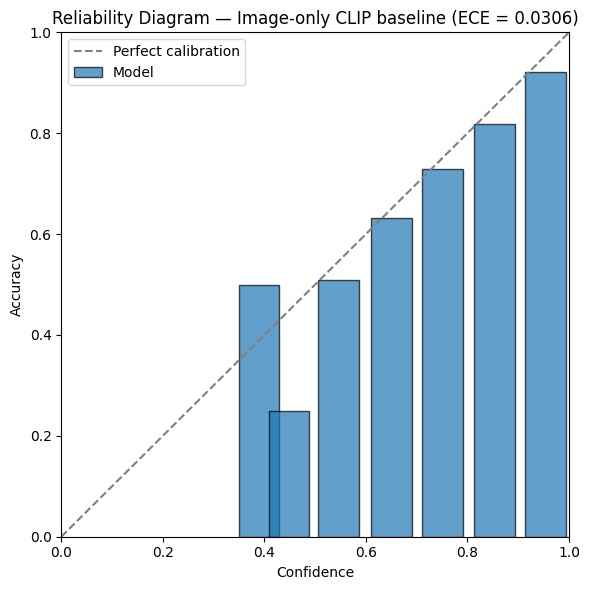

In [ ]:
bin_confidences = [b['confidence'] for b in bin_stats]
bin_accuracies = [b['accuracy'] for b in bin_stats]

fig, ax = plt.subplots(figsize=(6, 6))
ax.plot([0, 1], [0, 1], linestyle='--', color='gray', label='Perfect calibration')
ax.bar(bin_confidences, bin_accuracies, width=0.08, alpha=0.7, edgecolor='black', label='Model')
ax.set_xlabel('Confidence')
ax.set_ylabel('Accuracy')
ax.set_title(f'Reliability Diagram — Image-only CLIP baseline (ECE = {ece:.4f})')
ax.legend()
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
plt.tight_layout()

if not os.path.exists(FIGURE_PATH):
    plt.savefig(FIGURE_PATH, dpi=150)
plt.show()


## Step 8 — Compare against Stage 1 (text-only)

The real point of building both baselines separately: seeing where the modalities agree, and where one is doing more work than the other. This comparison also previews the "modality dominance" question.


In [ ]:
text_summary_path = f'{DRIVE_ROOT}/metadata/text_baseline_summary.json'

if os.path.exists(text_summary_path):
    with open(text_summary_path) as f:
        text_summary = json.load(f)
    tb = text_summary['text_baseline']

    comparison = pd.DataFrame({
        'Text-only (RoBERTa)': [tb['accuracy'], tb['macro_f1'], tb['auroc'], tb['ece']],
        'Image-only (CLIP)':   [acc, macro_f1, auroc, ece],
    }, index=['Accuracy', 'Macro-F1', 'AUROC', 'ECE'])

    print(comparison.round(4))
    print("\nNote: these were evaluated on different test sets (Stage 1's pre-filter split vs. this")
    print("notebook's image-confirmed split), so treat this as a directional comparison for now —")
    print("Stage 3 (fusion) will re-evaluate everything on one shared, aligned split.")
else:
    print("Stage 1 summary not found on Drive — skipping comparison.")


          Text-only (RoBERTa)  Image-only (CLIP)
Accuracy               0.7922             0.7656
Macro-F1               0.7045             0.7838
AUROC                  0.9086             0.8928
ECE                    0.0265             0.0306

Note: these were evaluated on different test sets (Stage 1's pre-filter split vs. this
notebook's image-confirmed split), so treat this as a directional comparison for now —
Stage 3 (fusion) will re-evaluate everything on one shared, aligned split.
